# SurfaceGuard AI - surface defect segmentation
Runs: `scratch-unet`, `pretrained-resnet34-unet`, `efficientnet-b0-unet`, plus an `ensemble-final` run.
#
How GPU time is saved:
- every image and mask is decoded once and kept in RAM, so the GPU never waits on file reading
- augmentation happens on the GPU
- mixed precision + channels_last
- early stopping and a per-model minute limit
- a short Optuna search (3 epochs on a third of the data) instead of guessing hyperparameters
#
What the prev logs showed, and what this version changes:
- defect_a and defect_b got Dice 0.00 in every model: the models never predicted them.
  Fix: batch-level dice per class, class-aware sampling, and per-class dice printed every epoch.
- the tuned thresholds always landed on the lowest value in the grid, so the grid now goes lower.
- efficientnet-b0 beat resnet34 by a wide margin, so the Optuna search now runs on efficientnet-b0.

In [1]:
import os, glob, random, shutil, time, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

try:
    import segmentation_models_pytorch as smp
except ImportError:
    os.system("pip install -q segmentation-models-pytorch")
    import segmentation_models_pytorch as smp

try:
    import optuna
except ImportError:
    os.system("pip install -q optuna")
    import optuna

import wandb

T_START = time.time()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.6/154.6 kB 7.1 MB/s eta 0:00:00


In [2]:
SEED = 42
H, W = 128, 800
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
BATCH = 32
VAL_FRAC = 0.15
RLE_ORDER = "F"
SAMPLE_BOOST = 0.5
EVAL_THR = 0.3
EVAL_CLS = 0.2
WANDB_PROJECT = "surface-defect-segmentation"
WORK = "/kaggle/working"

MAX_EPOCHS = {"scratch-unet": 12, "pretrained-resnet34-unet": 14, "efficientnet-b0-unet": 14}
MAX_MINUTES = {"scratch-unet": 10, "pretrained-resnet34-unet": 25, "efficientnet-b0-unet": 20}
PATIENCE = 5

N_TRIALS = 8
TUNE_EPOCHS = 3
TUNE_FRAC = 0.35
TUNE_VAL_MAX = 400

THRESHOLDS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
MIN_AREAS = [0, 40, 120, 300]
CLS_THRESHOLDS = [0.05, 0.1, 0.2, 0.35, 0.5]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
torch.backends.cudnn.benchmark = True
print("using", device)


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


seed_everything()

using cuda


In [3]:
found = glob.glob("/kaggle/input/**/train.csv", recursive=True)
assert found, "no train.csv found, is the competition data attached?"
DATA = os.path.dirname(found[0])
print("data folder:", DATA)

train_df = pd.read_csv(f"{DATA}/train.csv")
sample_sub = pd.read_csv(f"{DATA}/sample_submission.csv")
print(train_df.head())
print(sample_sub.head())

first = sample_sub["mask_rle"].iloc[0]
EMPTY_RLE = first if isinstance(first, str) else ""
print("empty mask will be written as:", repr(EMPTY_RLE))

img_paths = {}
for p in glob.glob(f"{DATA}/**/*", recursive=True):
    if p.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")):
        fname = os.path.basename(p)
        img_paths[fname] = p
        img_paths[os.path.splitext(fname)[0]] = p
print("images found:", len(img_paths) // 2)


def find_img(image_id):
    return img_paths[str(image_id)]

data folder: /kaggle/input/competitions/industrial-surface-defect-detection/public
     image_id defect_type                                           mask_rle  \
0  4S22I7SA34    defect_a  7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...   
1  4S22I7SA34    defect_b                                                NaN   
2  4S22I7SA34    defect_c                                                NaN   
3  4S22I7SA34    defect_d                                                NaN   
4  DZ899111OE    defect_a                                                NaN   

   width  height  
0    800     128  
1    800     128  
2    800     128  
3    800     128  
4    800     128  
   ID    image_id defect_type mask_rle
0   1  WAFNKCRR7Q    defect_a         
1   2  WAFNKCRR7Q    defect_b         
2   3  WAFNKCRR7Q    defect_c         
3   4  WAFNKCRR7Q    defect_d         
4   5  YZXKEWSUDD    defect_a         
empty mask will be written as: ' '
images found: 14393


In [4]:
def clean_rle(x):
    return x.strip() if isinstance(x, str) and x.strip() else ""


def rle_decode(rle, shape=(H, W)):
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    rle = clean_rle(rle)
    if rle:
        nums = [int(n) for n in rle.split()]
        for start, length in zip(nums[0::2], nums[1::2]):
            flat[start - 1:start - 1 + length] = 1
    return flat.reshape(shape, order=RLE_ORDER)


def rle_encode(mask):
    px = mask.flatten(order=RLE_ORDER)
    px = np.concatenate([[0], px, [0]])
    runs = np.where(px[1:] != px[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    return " ".join(str(r) for r in runs)


real = [clean_rle(r) for r in train_df["mask_rle"] if clean_rle(r)][:200]
for r in real:
    assert rle_encode(rle_decode(r)) == r, "RLE round trip failed"
print("rle round trip ok for", len(real), "masks")

rle_by_img = {}
for img_id, g in train_df.groupby("image_id"):
    d = dict(zip(g["defect_type"], g["mask_rle"]))
    rle_by_img[img_id] = [clean_rle(d.get(c, "")) for c in CLASSES]
print("train images:", len(rle_by_img))

rle round trip ok for 200 masks
train images: 11393


      class  images with it  fraction
0  defect_a            1081     0.095
1  defect_b             313     0.027
2  defect_c            4100     0.360
3  defect_d            1707     0.150


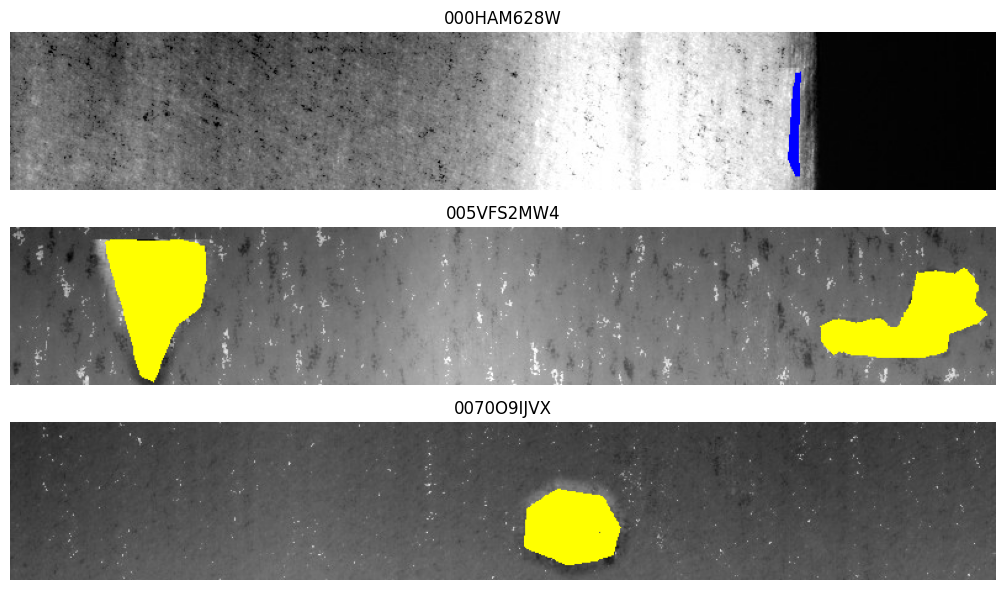

In [5]:
has = np.array([[bool(r) for r in rles] for rles in rle_by_img.values()])
print(pd.DataFrame({"class": CLASSES, "images with it": has.sum(0), "fraction": has.mean(0).round(3)}))

colors = [(255, 0, 0), (0, 255, 0), (0, 0, 255), (255, 255, 0)]
fig, axes = plt.subplots(3, 1, figsize=(14, 6))
shown = 0
for img_id, rles in rle_by_img.items():
    if shown == 3:
        break
    if not any(rles):
        continue
    img = cv2.imread(find_img(img_id), cv2.IMREAD_GRAYSCALE)
    assert img.shape == (H, W), f"image is {img.shape}, expected {(H, W)}"
    overlay = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    for c, r in enumerate(rles):
        overlay[rle_decode(r) == 1] = colors[c]
    axes[shown].imshow(overlay)
    axes[shown].set_title(img_id)
    axes[shown].axis("off")
    shown += 1
plt.tight_layout()
plt.show()

In [6]:
ids = np.array(sorted(rle_by_img.keys()))
combo = np.array(["".join("1" if r else "0" for r in rle_by_img[i]) for i in ids])
vc = pd.Series(combo).value_counts()
strat = np.where(vc[combo].values >= 3, combo, "rare")
if pd.Series(strat).value_counts().min() < 2:
    strat = None

train_ids, val_ids = train_test_split(ids, test_size=VAL_FRAC, random_state=SEED, stratify=strat)
print("train:", len(train_ids), "val:", len(val_ids))
print("val positives per class:", [sum(1 for i in val_ids if rle_by_img[i][c]) for c in range(4)])

train: 9684 val: 1709
val positives per class: [162, 48, 615, 256]


In [7]:
def load_gray(image_ids):
    out = np.zeros((len(image_ids), H, W), dtype=np.uint8)
    for k, i in enumerate(image_ids):
        out[k] = cv2.imread(find_img(i), cv2.IMREAD_GRAYSCALE)
    return torch.from_numpy(out)


t0 = time.time()
all_ids = list(ids)
pos_of = {i: k for k, i in enumerate(all_ids)}
X_all = load_gray(all_ids)
Y_np = np.zeros((len(all_ids), 4, H, W), dtype=np.uint8)
for k, i in enumerate(all_ids):
    for c, r in enumerate(rle_by_img[i]):
        Y_np[k, c] = rle_decode(r)
Y_all = torch.from_numpy(Y_np)
print("cached", tuple(X_all.shape), tuple(Y_all.shape), f"in {time.time() - t0:.0f}s")

train_idx = torch.tensor([pos_of[i] for i in train_ids])
val_idx = torch.tensor([pos_of[i] for i in val_ids])

present = Y_all.flatten(2).amax(2).float()
class_freq = present[train_idx].mean(0).clamp(min=1e-3)
print("class frequency in train:", dict(zip(CLASSES, class_freq.numpy().round(3))))
POS_W = 1.0 + SAMPLE_BOOST * (present / class_freq.sqrt()).amax(1)

test_ids = sample_sub["image_id"].unique().tolist()
X_test = load_gray(test_ids)
print("test images:", len(test_ids))

MEAN, STD = 0.449, 0.226


def to_input(x_uint8):
    x = x_uint8.to(device).float().div(255)
    x = (x - MEAN) / STD
    return x.unsqueeze(1).repeat(1, 3, 1, 1).contiguous(memory_format=torch.channels_last)


def get_batch(idx, augment=False):
    x = X_all[idx].to(device).float().div(255)
    y = Y_all[idx].to(device).float()
    if augment:
        n = len(idx)
        hf = torch.rand(n, device=device) < 0.5
        x[hf] = x[hf].flip(-1)
        y[hf] = y[hf].flip(-1)
        vf = torch.rand(n, device=device) < 0.5
        x[vf] = x[vf].flip(-2)
        y[vf] = y[vf].flip(-2)
        a = torch.empty(n, 1, 1, device=device).uniform_(0.85, 1.15)
        b = torch.empty(n, 1, 1, device=device).uniform_(-0.05, 0.05)
        jit = torch.rand(n, 1, 1, device=device) < 0.5
        x = torch.where(jit, (x * a + b).clamp(0, 1), x)
    x = (x - MEAN) / STD
    x = x.unsqueeze(1).repeat(1, 3, 1, 1).contiguous(memory_format=torch.channels_last)
    return x, y


AUGS = "hflip, vflip, brightness/contrast jitter (on GPU), rare-class oversampling"

cached (11393, 128, 800) (11393, 4, 128, 800) in 75s
class frequency in train: {'defect_a': np.float32(0.095), 'defect_b': np.float32(0.027), 'defect_c': np.float32(0.36), 'defect_d': np.float32(0.15)}
test images: 3000


In [8]:
def double_conv(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
    )


class SmallUNet(nn.Module):
    def __init__(self, in_ch=3, n_cls=4, base=24):
        super().__init__()
        b = base
        self.enc1 = double_conv(in_ch, b)
        self.enc2 = double_conv(b, b * 2)
        self.enc3 = double_conv(b * 2, b * 4)
        self.enc4 = double_conv(b * 4, b * 8)
        self.mid = double_conv(b * 8, b * 16)
        self.pool = nn.MaxPool2d(2)

        self.up4 = nn.ConvTranspose2d(b * 16, b * 8, 2, stride=2)
        self.dec4 = double_conv(b * 16, b * 8)
        self.up3 = nn.ConvTranspose2d(b * 8, b * 4, 2, stride=2)
        self.dec3 = double_conv(b * 8, b * 4)
        self.up2 = nn.ConvTranspose2d(b * 4, b * 2, 2, stride=2)
        self.dec2 = double_conv(b * 4, b * 2)
        self.up1 = nn.ConvTranspose2d(b * 2, b, 2, stride=2)
        self.dec1 = double_conv(b * 2, b)
        self.out = nn.Conv2d(b, n_cls, 1)
        self.cls_head = nn.Sequential(nn.Dropout(0.2), nn.Linear(b * 16, n_cls))

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        m = self.mid(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(m), e4], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))
        return self.out(d1), self.cls_head(m.mean((2, 3)))


def build_scratch(attn="none"):
    return SmallUNet()


def build_resnet34(attn="none"):
    return smp.Unet("resnet34", encoder_weights="imagenet", in_channels=3, classes=4,
                    aux_params={"classes": 4, "dropout": 0.2},
                    decoder_attention_type=None if attn == "none" else attn)


def build_effnet(attn="none"):
    return smp.Unet("efficientnet-b0", encoder_weights="imagenet", in_channels=3, classes=4,
                    aux_params={"classes": 4, "dropout": 0.2},
                    decoder_attention_type=None if attn == "none" else attn)

In [9]:
def total_loss(seg, cls, y, hp):
    bce = F.binary_cross_entropy_with_logits(seg, y)
    p = torch.sigmoid(seg)
    inter = (p * y).sum((0, 2, 3))
    total = p.sum((0, 2, 3)) + y.sum((0, 2, 3))
    dice_loss = 1 - ((2 * inter + 1) / (total + 1)).mean()
    present = (y.amax(dim=(2, 3)) > 0).float()
    cls_loss = F.binary_cross_entropy_with_logits(cls, present)
    return bce + hp["dice_w"] * dice_loss + hp["cls_w"] * cls_loss


def pair_stats(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    return (pred & gt).sum((2, 3)), pred.sum((2, 3)), gt.sum((2, 3))


def scores_from_stats(inter, parea, garea):
    inter, parea, garea = np.asarray(inter).ravel(), np.asarray(parea).ravel(), np.asarray(garea).ravel()
    empty = garea == 0
    dice = 2 * inter / np.maximum(parea + garea, 1)
    fg = dice[~empty].mean() if (~empty).any() else 0.0
    fp = (parea[empty] == 0).mean() if empty.any() else 1.0
    acc = ((parea == 0) == empty).mean()
    return {"fg_dice": float(fg), "fp_score": float(fp), "empty_acc": float(acc),
            "weighted": float(0.7 * fg + 0.2 * fp + 0.1 * acc)}


def class_report(masks, gts):
    rows = []
    for c in range(4):
        s = scores_from_stats(*pair_stats(masks[:, c:c + 1], gts[:, c:c + 1]))
        rows.append({"class": CLASSES[c], "positives": int((gts[:, c].sum((1, 2)) > 0).sum()),
                     **{k: round(v, 4) for k, v in s.items()}})
    return pd.DataFrame(rows)


@torch.no_grad()
def evaluate(model, idx, hp):
    model.eval()
    loss_sum, n = 0.0, 0
    inters, pareas, gareas = [], [], []
    for s in range(0, len(idx), 64):
        b = idx[s:s + 64]
        x, y = get_batch(b)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            seg, cls = model(x)
        seg, cls = seg.float(), cls.float()
        loss_sum += total_loss(seg, cls, y, hp).item() * len(b)
        n += len(b)
        pred = (torch.sigmoid(seg) > EVAL_THR) & (torch.sigmoid(cls) > EVAL_CLS)[:, :, None, None]
        yb = y > 0.5
        inters.append((pred & yb).sum((2, 3)).cpu())
        pareas.append(pred.sum((2, 3)).cpu())
        gareas.append(yb.sum((2, 3)).cpu())
    I, P, G = torch.cat(inters).numpy(), torch.cat(pareas).numpy(), torch.cat(gareas).numpy()
    sc = scores_from_stats(I, P, G)
    for c in range(4):
        sc[f"dice_{CLASSES[c][-1]}"] = scores_from_stats(I[:, c], P[:, c], G[:, c])["fg_dice"]
    return loss_sum / n, sc


def fit(model, hp, epochs, tr_idx, va_idx, max_minutes=None, patience=PATIENCE,
        ckpt_path=None, on_epoch=None):
    opt = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["wd"])
    steps = max(1, len(tr_idx) // BATCH)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=hp["lr"], total_steps=epochs * steps, pct_start=0.15)
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    weights = POS_W[tr_idx]

    history, best_score, best_epoch, bad = [], -1.0, 0, 0
    t_fit = time.time()
    for ep in range(1, epochs + 1):
        t_ep = time.time()
        model.train()
        order = tr_idx[torch.multinomial(weights, len(tr_idx), replacement=True)]
        loss_sum, n = 0.0, 0
        for s in range(steps):
            b = order[s * BATCH:(s + 1) * BATCH]
            x, y = get_batch(b, augment=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                seg, cls = model(x)
            loss = total_loss(seg.float(), cls.float(), y, hp)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            loss_sum += loss.item() * len(b)
            n += len(b)

        train_loss = loss_sum / n
        val_loss, sc = evaluate(model, va_idx, hp)
        history.append({"epoch": ep, "train_loss": train_loss, "val_loss": val_loss, **sc})
        ep_time = time.time() - t_ep
        print(f"epoch {ep}/{epochs}  train {train_loss:.4f}  val {val_loss:.4f}  "
              f"dice {sc['fg_dice']:.4f}  score {sc['weighted']:.4f}  "
              f"[a {sc['dice_a']:.2f} b {sc['dice_b']:.2f} c {sc['dice_c']:.2f} d {sc['dice_d']:.2f}]  ({ep_time:.0f}s)")
        if on_epoch is not None:
            on_epoch(ep, train_loss, val_loss, sc, opt.param_groups[0]["lr"])

        if sc["weighted"] > best_score:
            best_score, best_epoch, bad = sc["weighted"], ep, 0
            if ckpt_path is not None:
                torch.save(model.state_dict(), ckpt_path)
        else:
            bad += 1
            if bad >= patience:
                print(f"   no improvement for {patience} epochs, stopping")
                break
        if max_minutes is not None and (time.time() - t_fit) + ep_time > max_minutes * 60:
            print(f"   hit the {max_minutes} minute limit, stopping")
            break
    return history, best_epoch, best_score

In [10]:
@torch.no_grad()
def get_probs(models, x):
    seg_sum, cls_sum, count = 0, 0, 0
    for m in models:
        for flip in (False, True):
            xin = torch.flip(x, dims=[-1]) if flip else x
            with torch.autocast(device_type=device.type, enabled=use_amp):
                seg, cls = m(xin)
            seg, cls = torch.sigmoid(seg.float()), torch.sigmoid(cls.float())
            if flip:
                seg = torch.flip(seg, dims=[-1])
            seg_sum = seg_sum + seg
            cls_sum = cls_sum + cls
            count += 1
    return seg_sum / count, cls_sum / count


@torch.no_grad()
def predict_val(models):
    for m in models:
        m.eval()
    segs, clss = [], []
    for s in range(0, len(val_idx), 64):
        b = val_idx[s:s + 64]
        seg, cls = get_probs(models, to_input(X_all[b]))
        segs.append(seg.cpu().numpy().astype(np.float16))
        clss.append(cls.cpu().numpy())
    return np.concatenate(segs), np.concatenate(clss), Y_all[val_idx].numpy()


def remove_small(mask, min_area):
    if min_area <= 0 or not mask.any():
        return mask
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    out = np.zeros_like(mask)
    for k in range(1, n):
        if stats[k, cv2.CC_STAT_AREA] >= min_area:
            out[labels == k] = 1
    return out


def tune_on_val(seg, cls, gts):
    params = []
    for c in range(4):
        g = gts[:, c:c + 1]
        garea = g.sum((2, 3))
        best = {"score": -1, "thr": 0.5, "min_area": 0, "cls_thr": 0.5}
        for thr in THRESHOLDS:
            binary = (seg[:, c] > thr).astype(np.uint8)
            for area in MIN_AREAS:
                m = binary if area == 0 else np.stack([remove_small(b, area) for b in binary])
                inter, parea, _ = pair_stats(m[:, None], g)
                for ct in CLS_THRESHOLDS:
                    keep = (cls[:, c] > ct)[:, None]
                    s = scores_from_stats(inter * keep, parea * keep, garea)["weighted"]
                    if s > best["score"]:
                        best = {"score": s, "thr": thr, "min_area": area, "cls_thr": ct}
        params.append({"thr": best["thr"], "min_area": best["min_area"], "cls_thr": best["cls_thr"]})
        print(f"  {CLASSES[c]}: thr={best['thr']} min_area={best['min_area']} "
              f"cls_thr={best['cls_thr']} val_score={best['score']:.4f}")
    return params


def apply_post(seg, cls, params):
    out = np.zeros(seg.shape, dtype=np.uint8)
    for c in range(4):
        binary = (seg[:, c] > params[c]["thr"]).astype(np.uint8)
        cleaned = np.stack([remove_small(b, params[c]["min_area"]) for b in binary])
        keep = cls[:, c] > params[c]["cls_thr"]
        out[:, c] = cleaned * keep[:, None, None]
    return out


@torch.no_grad()
def predict_test(models, params):
    for m in models:
        m.eval()
    preds = {}
    for s in range(0, len(test_ids), 64):
        seg, cls = get_probs(models, to_input(X_test[s:s + 64]))
        masks = apply_post(seg.cpu().numpy(), cls.cpu().numpy(), params)
        for b in range(masks.shape[0]):
            for c in range(4):
                m = masks[b, c]
                preds[(test_ids[s + b], CLASSES[c])] = rle_encode(m) if m.any() else EMPTY_RLE
    return preds


def write_submission(preds, path):
    sub = sample_sub.copy()
    sub["mask_rle"] = [preds.get((i, d), EMPTY_RLE) for i, d in zip(sub["image_id"], sub["defect_type"])]
    assert list(sub.columns) == list(sample_sub.columns)
    assert len(sub) == len(sample_sub)
    sub.to_csv(path, index=False)

In [11]:
from kaggle_secrets import UserSecretsClient

wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: amitoj (24f2002444) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [12]:
rng = np.random.default_rng(SEED)
tune_idx = train_idx[torch.from_numpy(rng.permutation(len(train_idx))[: int(len(train_idx) * TUNE_FRAC)])]
tune_val_idx = val_idx[:TUNE_VAL_MAX]
print("search uses", len(tune_idx), "train images and", len(tune_val_idx), "val images")


def objective(trial):
    hp = {"lr": trial.suggest_float("lr", 1e-4, 1e-3, log=True),
          "wd": trial.suggest_float("wd", 1e-5, 1e-3, log=True),
          "cls_w": trial.suggest_float("cls_w", 0.1, 1.0),
          "dice_w": trial.suggest_float("dice_w", 0.5, 2.0)}
    attn = trial.suggest_categorical("attn", ["none", "scse"])
    seed_everything(SEED)
    model = build_effnet(attn).to(device).to(memory_format=torch.channels_last)

    def report(ep, train_loss, val_loss, sc, lr):
        trial.report(sc["weighted"], ep)
        if trial.should_prune():
            raise optuna.TrialPruned()

    try:
        _, _, best = fit(model, hp, TUNE_EPOCHS, tune_idx, tune_val_idx, patience=TUNE_EPOCHS, on_epoch=report)
    finally:
        del model
        torch.cuda.empty_cache()
    return best


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=1))
study.optimize(objective, n_trials=N_TRIALS)

print(study.trials_dataframe()[["number", "value", "state"] + [c for c in study.trials_dataframe().columns if c.startswith("params_")]])
best_hp = dict(study.best_params)
print("best hyperparameters:", best_hp)

[I 2026-11-09 16:57:54,755] A new study created in memory with name: no-name-b8349a6a-64fa-48ed-b87f-6470badfd554


search uses 3389 train images and 400 val images


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch 1/3  train 2.5988  val 2.3428  dice 0.1532  score 0.1784  [a 0.02 b 0.01 c 0.18 d 0.20]  (126s)
epoch 2/3  train 2.0242  val 2.0004  dice 0.2951  score 0.3084  [a 0.01 b 0.02 c 0.32 d 0.44]  (34s)


... (12 outputs left out)

[I 2026-11-09 17:12:07,133] Trial 6 pruned. 


epoch 1/3  train 1.9886  val 1.9460  dice 0.1889  score 0.1989  [a 0.01 b 0.00 c 0.17 d 0.38]  (47s)


[I 2026-11-09 17:12:54,846] Trial 7 pruned. 


epoch 1/3  train 2.1162  val 2.0548  dice 0.2203  score 0.2035  [a 0.02 b 0.01 c 0.25 d 0.31]  (47s)
   number     value     state params_attn  params_cls_w  params_dice_w  \
0       0  0.326744  COMPLETE        none      0.758795       1.397988   
1       1  0.308110  COMPLETE        scse      0.641004       1.562109   
2       2  0.565828  COMPLETE        scse      0.263642       0.775107   
3       3  0.426872  COMPLETE        scse      0.650668       0.709241   
4       4  0.345818    PRUNED        none      0.279706       1.271352   
5       5  0.431798  COMPLETE        none      0.158546       1.923328   
6       6  0.198922    PRUNED        scse      0.715810       1.160229   
7       7  0.203514    PRUNED        scse      0.332902       1.493783   

   params_lr  params_wd  
0   0.000237   0.000797  
1   0.000114   0.000540  
2   0.000680   0.000027  
3   0.000270   0.000038  
4   0.000286   0.000372  
5   0.000405   0.000022  
6   0.000202   0.000016  
7   0.000108   0.000659 

In [13]:
def run_experiment(name, build_fn, encoder, pretrained, hp, attn):
    seed_everything(SEED)
    epochs = MAX_EPOCHS[name]
    config = {"seed": SEED, "encoder": encoder, "pretrained": pretrained, **hp, "decoder_attention": attn,
              "max_epochs": epochs, "patience": PATIENCE, "max_minutes": MAX_MINUTES[name],
              "batch_size": BATCH, "augmentations": AUGS,
              "loss": "BCE + dice_w * soft dice + cls_w * presence BCE",
              "optimizer": "AdamW", "scheduler": "OneCycle", "val_frac": VAL_FRAC,
              "image_size": f"{H}x{W}"}
    run = wandb.init(project=WANDB_PROJECT, name=name, config=config, reinit=True)
    assert run is not None, "wandb run didn't start"
    print(f"\n=== {name} === {run.url}")

    model = build_fn(attn).to(device).to(memory_format=torch.channels_last)
    ckpt_path = f"{WORK}/{name}_best.pth"

    def log_epoch(ep, train_loss, val_loss, sc, lr):
        wandb.log({"train_loss": train_loss, "val_loss": val_loss, "val_fg_dice": sc["fg_dice"],
                   "val_fp_score": sc["fp_score"], "val_empty_acc": sc["empty_acc"],
                   "val_weighted": sc["weighted"], "lr": lr,
                   **{f"val_dice_{k}": sc[f"dice_{k}"] for k in "abcd"}}, step=ep)

    history, best_epoch, _ = fit(model, hp, epochs, train_idx, val_idx, max_minutes=MAX_MINUTES[name],
                                 ckpt_path=ckpt_path, on_epoch=log_epoch)

    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()
    print("best epoch:", best_epoch, "- tuning on val")
    seg, cls, gts = predict_val([model])
    params = tune_on_val(seg, cls, gts)
    masks = apply_post(seg, cls, params)
    tuned = scores_from_stats(*pair_stats(masks, gts))
    print("val after tuning:", {k: round(v, 4) for k, v in tuned.items()})
    print(class_report(masks, gts))
    del seg, cls, masks, gts

    sub_path = f"{WORK}/submission_{name}.csv"
    write_submission(predict_test([model], params), sub_path)

    best_row = history[best_epoch - 1]
    run.summary.update({"best_epoch": best_epoch,
                        "best_train_loss": best_row["train_loss"],
                        "best_val_loss": best_row["val_loss"],
                        "tuned_fg_dice": tuned["fg_dice"], "tuned_fp_score": tuned["fp_score"],
                        "tuned_empty_acc": tuned["empty_acc"], "tuned_weighted": tuned["weighted"],
                        "thresholds": {CLASSES[c]: params[c] for c in range(4)}})

    ckpt_art = wandb.Artifact(f"{name}-checkpoint", type="model")
    ckpt_art.add_file(ckpt_path)
    run.log_artifact(ckpt_art)
    sub_art = wandb.Artifact(f"{name}-submission", type="submission")
    sub_art.add_file(sub_path)
    run.log_artifact(sub_art)

    wandb.finish()
    torch.cuda.empty_cache()
    return {"model": name, "net": model, "history": history, "sub_path": sub_path,
            "best_epoch": best_epoch, "train_loss": best_row["train_loss"],
            "val_loss": best_row["val_loss"], "fg_dice": tuned["fg_dice"],
            "fp_score": tuned["fp_score"], "empty_acc": tuned["empty_acc"],
            "weighted": tuned["weighted"]}


hp_model = {k: best_hp[k] for k in ["lr", "wd", "cls_w", "dice_w"]}
attn = best_hp["attn"]
hp_scratch = {**hp_model, "lr": 1e-3}

results = []
results.append(run_experiment("scratch-unet", build_scratch, "none (custom unet)", False, hp_scratch, "none"))
results.append(run_experiment("pretrained-resnet34-unet", build_resnet34, "resnet34", True, hp_model, attn))
results.append(run_experiment("efficientnet-b0-unet", build_effnet, "efficientnet-b0", True, hp_model, attn))

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.
wandb: setting up run 2jygz45i
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261109_171255-2jygz45i
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run scratch-unet
wandb: ⭐️ View project at https://wandb.ai/24f2002444/surface-defect-segmentation
wandb: 🚀 View run at https://wandb.ai/24f2002444/surface-defect-segmentation/runs/2jygz45i



=== scratch-unet === https://wandb.ai/24f2002444/surface-defect-segmentation/runs/2jygz45i
epoch 1/12  train 1.5034  val 1.2568  dice 0.1233  score 0.2577  [a 0.01 b 0.00 c 0.17 d 0.10]  (120s)
epoch 2/12  train 1.0419  val 0.8938  dice 0.1176  score 0.3422  [a 0.00 b 0.00 c 0.18 d 0.07]  (104s)
epoch 3/12  train 0.8558  val 0.8403  dice 0.2003  score 0.3952  [a 0.00 b 0.00 c 0.34 d 0.03]  (104s)
epoch 4/12  train 0.7794  val 0.7424  dice 0.2953  score 0.4732  [a 0.00 b 0.00 c 0.33 d 0.46]  (105s)
epoch 5/12  train 0.7458  val 0.7795  dice 0.3244  score 0.4807  [a 0.00 b 0.00 c 0.38 d 0.45]  (104s)
   hit the 10 minute limit, stopping
best epoch: 5 - tuning on val
  defect_a: thr=0.1 min_area=0 cls_thr=0.2 val_score=0.2905
  defect_b: thr=0.1 min_area=0 cls_thr=0.05 val_score=0.2972
  defect_c: thr=0.6 min_area=300 cls_thr=0.2 val_score=0.4650
  defect_d: thr=0.2 min_area=300 cls_thr=0.2 val_score=0.5806
val after tuning: {'fg_dice': 0.3281, 'fp_score': 0.8902, 'empty_acc': 0.8451, 'w

wandb: updating run metadata; uploading artifact scratch-unet-checkpoint; uploading artifact scratch-unet-submission
wandb: uploading artifact scratch-unet-checkpoint; uploading artifact scratch-unet-submission
wandb: uploading artifact scratch-unet-checkpoint; uploading artifact scratch-unet-submission; uploading history steps 4-4, summary
wandb: uploading artifact scratch-unet-checkpoint; uploading artifact scratch-unet-submission
wandb: uploading artifact scratch-unet-checkpoint; uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: uploading artifact scratch-unet-checkpoint; uploading output.log; uploading config.yaml
wandb: uploading data
wandb: 
wandb: Run history:
wandb:            lr ▁█▇▆▄
wandb:    train_loss █▄▂▁▁
wandb:    val_dice_a █▁▁▁▁
wandb:    val_dice_b █▁▁▁▁
wandb:    val_dice_c ▁▁▇▆█
wandb:    val_dice_d ▂▂▁██
wandb: val_empty_acc ▁▇▇█▇
wandb:   val_fg_dice ▁▁▄▇█
wandb:  val_fp_score ▁█▇█▇
wandb:      val_loss █▃▂▁▂
wandb:            +1 ..


=== pretrained-resnet34-unet === https://wandb.ai/24f2002444/surface-defect-segmentation/runs/fv1bt7ba


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch 1/14  train 1.3022  val 0.9886  dice 0.2681  score 0.4230  [a 0.03 b 0.04 c 0.30 d 0.39]  (150s)
epoch 2/14  train 0.7267  val 0.7680  dice 0.2424  score 0.4173  [a 0.12 b 0.14 c 0.24 d 0.33]  (138s)
epoch 3/14  train 0.6316  val 0.6454  dice 0.3684  score 0.5264  [a 0.24 b 0.22 c 0.42 d 0.36]  (138s)
epoch 4/14  train 0.5850  val 0.6302  dice 0.3629  score 0.5273  [a 0.25 b 0.17 c 0.42 d 0.34]  (138s)
epoch 5/14  train 0.5615  val 0.5692  dice 0.3834  score 0.5485  [a 0.20 b 0.22 c 0.42 d 0.43]  (138s)
epoch 6/14  train 0.5201  val 0.5299  dice 0.4435  score 0.5882  [a 0.28 b 0.20 c 0.45 d 0.57]  (138s)
epoch 7/14  train 0.5006  val 0.5273  dice 0.4339  score 0.5859  [a 0.22 b 0.21 c 0.47 d 0.51]  (138s)
epoch 8/14  train 0.4652  val 0.5005  dice 0.4763  score 0.6160  [a 0.27 b 0.18 c 0.50 d 0.61]  (139s)
epoch 9/14  train 0.4457  val 0.4839  dice 0.4797  score 0.6178  [a 0.27 b 0.26 c 0.51 d 0.58]  (139s)
epoch 10/14  train 0.4364  val 0.4683  dice 0.4785  score 0.6182  [a 0.27

wandb: updating run metadata; uploading artifact pretrained-resnet34-unet-checkpoint; uploading artifact pretrained-resnet34-unet-submission
wandb: uploading artifact pretrained-resnet34-unet-checkpoint; uploading artifact pretrained-resnet34-unet-submission
wandb: uploading artifact pretrained-resnet34-unet-checkpoint; uploading artifact pretrained-resnet34-unet-submission; uploading history steps 9-9, summary
wandb: uploading artifact pretrained-resnet34-unet-checkpoint; uploading artifact pretrained-resnet34-unet-submission
wandb: uploading artifact pretrained-resnet34-unet-checkpoint
wandb: uploading artifact pretrained-resnet34-unet-checkpoint; uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: uploading artifact pretrained-resnet34-unet-checkpoint; uploading wandb-summary.json; uploading config.yaml
wandb: uploading artifact pretrained-resnet34-unet-checkpoint
wandb: uploading data
wandb: 
wandb: Run history:
wandb:            lr ▃██▇▇▆▅▃▂▁
wandb:   


=== efficientnet-b0-unet === https://wandb.ai/24f2002444/surface-defect-segmentation/runs/3x2o8dte
epoch 1/14  train 1.1919  val 0.8717  dice 0.3664  score 0.4082  [a 0.00 b 0.00 c 0.41 d 0.57]  (152s)
epoch 2/14  train 0.7070  val 0.6616  dice 0.4196  score 0.5660  [a 0.00 b 0.00 c 0.48 d 0.62]  (138s)
epoch 3/14  train 0.6213  val 0.5920  dice 0.4406  score 0.5910  [a 0.24 b 0.00 c 0.49 d 0.54]  (138s)
epoch 4/14  train 0.5507  val 0.5320  dice 0.4165  score 0.5794  [a 0.24 b 0.00 c 0.40 d 0.65]  (138s)
epoch 5/14  train 0.5207  val 0.5337  dice 0.4893  score 0.6244  [a 0.26 b 0.00 c 0.51 d 0.69]  (138s)
epoch 6/14  train 0.4900  val 0.4877  dice 0.5077  score 0.6357  [a 0.23 b 0.23 c 0.55 d 0.63]  (138s)
epoch 7/14  train 0.4378  val 0.4456  dice 0.5131  score 0.6482  [a 0.27 b 0.24 c 0.53 d 0.69]  (138s)
epoch 8/14  train 0.3997  val 0.4515  dice 0.5204  score 0.6512  [a 0.29 b 0.17 c 0.54 d 0.67]  (138s)
   hit the 20 minute limit, stopping
best epoch: 8 - tuning on val
  defect_

wandb: updating run metadata; uploading artifact efficientnet-b0-unet-checkpoint; uploading artifact efficientnet-b0-unet-submission
wandb: uploading artifact efficientnet-b0-unet-checkpoint; uploading artifact efficientnet-b0-unet-submission
wandb: uploading artifact efficientnet-b0-unet-checkpoint; uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: uploading artifact efficientnet-b0-unet-checkpoint; uploading wandb-summary.json; uploading config.yaml
wandb: uploading artifact efficientnet-b0-unet-checkpoint
wandb: 
wandb: Run history:
wandb:            lr ▁██▇▆▅▃▁
wandb:    train_loss █▄▃▂▂▂▁▁
wandb:    val_dice_a ▁▁▇▇▇▆▇█
wandb:    val_dice_b ▁▁▁▁▁██▆
wandb:    val_dice_c ▁▅▅▁▆█▇█
wandb:    val_dice_d ▂▅▁▆█▅█▇
wandb: val_empty_acc ▁▇██████
wandb:   val_fg_dice ▁▃▄▃▇▇██
wandb:  val_fp_score ▁▇███▇██
wandb:      val_loss █▅▃▂▂▂▁▁
wandb:            +1 ...
wandb: 
wandb: Run summary:
wandb:      best_epoch 8
wandb: best_train_loss 0.39975
wandb:   best_val_

In [14]:
nets = {r["model"]: r["net"] for r in results}
member_names = ["pretrained-resnet34-unet", "efficientnet-b0-unet"]
members = [nets[n] for n in member_names]

print("tuning the ensemble")
seg, cls, gts = predict_val(members)
ens_params = tune_on_val(seg, cls, gts)
ens_masks = apply_post(seg, cls, ens_params)
ens_tuned = scores_from_stats(*pair_stats(ens_masks, gts))
print("ensemble val:", {k: round(v, 4) for k, v in ens_tuned.items()})
print(class_report(ens_masks, gts))
del seg, cls, ens_masks, gts

run = wandb.init(project=WANDB_PROJECT, name="ensemble-final", reinit=True,
                 config={"seed": SEED, "members": member_names, "tta": "hflip", "val_frac": VAL_FRAC,
                         "averaging": "mean of probabilities (segmentation + presence)"})
assert run is not None, "wandb run didn't start"
ens_sub_path = f"{WORK}/submission_ensemble-final.csv"
write_submission(predict_test(members, ens_params), ens_sub_path)
run.summary.update({"tuned_fg_dice": ens_tuned["fg_dice"], "tuned_fp_score": ens_tuned["fp_score"],
                    "tuned_empty_acc": ens_tuned["empty_acc"], "tuned_weighted": ens_tuned["weighted"],
                    "thresholds": {CLASSES[c]: ens_params[c] for c in range(4)}})
art = wandb.Artifact("ensemble-final-submission", type="submission")
art.add_file(ens_sub_path)
run.log_artifact(art)
wandb.finish()

tuning the ensemble
  defect_a: thr=0.2 min_area=120 cls_thr=0.1 val_score=0.5019
  defect_b: thr=0.1 min_area=40 cls_thr=0.1 val_score=0.5460
  defect_c: thr=0.3 min_area=40 cls_thr=0.2 val_score=0.6584
  defect_d: thr=0.1 min_area=40 cls_thr=0.2 val_score=0.7752
ensemble val: {'fg_dice': 0.5456, 'fp_score': 0.9454, 'empty_acc': 0.9241, 'weighted': 0.6634}
      class  positives  fg_dice  fp_score  empty_acc  weighted
0  defect_a        162   0.3175    0.9444     0.9075    0.5019
1  defect_b         48   0.3716    0.9554     0.9479    0.5460
2  defect_c        615   0.5577    0.8995     0.8812    0.6584
3  defect_d        256   0.6932    0.9697     0.9596    0.7752


wandb: setting up run jj2a6s84
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261109_181553-jj2a6s84
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run ensemble-final
wandb: ⭐️ View project at https://wandb.ai/24f2002444/surface-defect-segmentation
wandb: 🚀 View run at https://wandb.ai/24f2002444/surface-defect-segmentation/runs/jj2a6s84
wandb: updating run metadata; uploading artifact ensemble-final-submission
wandb: uploading artifact ensemble-final-submission
wandb: uploading artifact ensemble-final-submission; uploading summary
wandb: uploading artifact ensemble-final-submission
wandb: uploading wandb-summary.json; uploading config.yaml
wandb: uploading config.yaml
wandb: uploading data
wandb: 
wandb: Run summary:
wandb: tuned_empty_acc 0.92408
wandb:   tuned_fg_dice 0.54556
wandb:  tuned_fp_score 0.94544
wandb:  tuned_weighted 0.66339
wandb: 
wandb: 🚀 View run ensemble-final at: https://wandb.ai/24f2002

                   model  fg_dice  empty_acc  fp_score  weighted  train_loss  val_loss  best_epoch
            scratch-unet   0.3281     0.8451    0.8902    0.4922      0.7458    0.7795         5.0
pretrained-resnet34-unet   0.4995     0.9241    0.9545    0.6329      0.4364    0.4683        10.0
    efficientnet-b0-unet   0.5418     0.9337    0.9606    0.6647      0.3997    0.4515         8.0
          ensemble-final   0.5456     0.9241    0.9454    0.6634         NaN       NaN         NaN


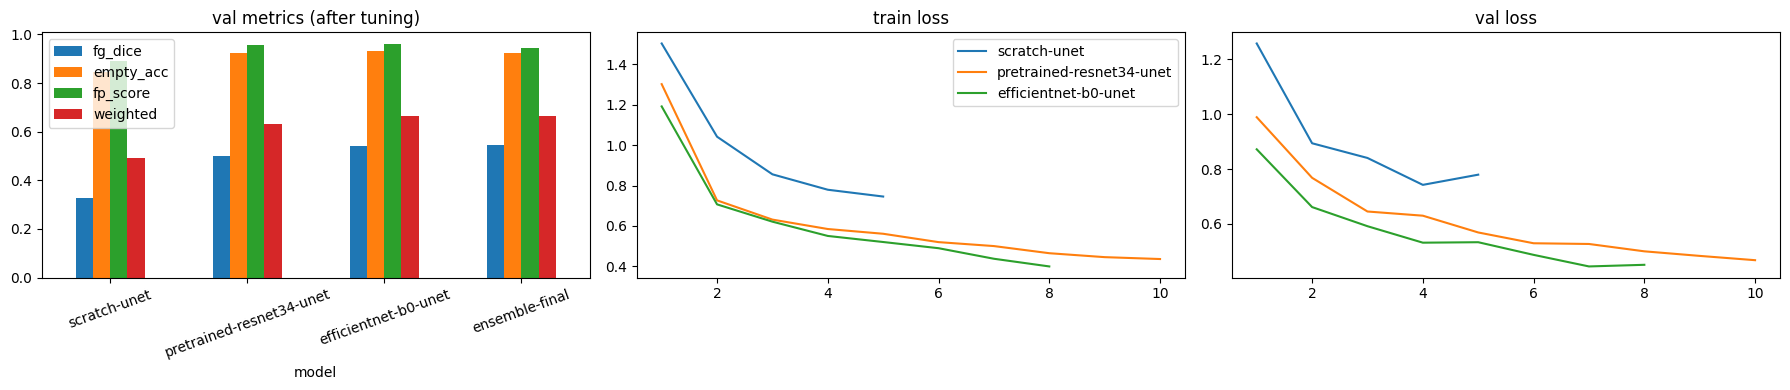

In [15]:
rows = [{k: r[k] for k in ["model", "fg_dice", "empty_acc", "fp_score", "weighted", "train_loss", "val_loss", "best_epoch"]}
        for r in results]
rows.append({"model": "ensemble-final", "fg_dice": ens_tuned["fg_dice"], "empty_acc": ens_tuned["empty_acc"],
             "fp_score": ens_tuned["fp_score"], "weighted": ens_tuned["weighted"],
             "train_loss": np.nan, "val_loss": np.nan, "best_epoch": np.nan})
comp = pd.DataFrame(rows).round(4)
comp.to_csv(f"{WORK}/model_comparison.csv", index=False)
print(comp.to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
comp.set_index("model")[["fg_dice", "empty_acc", "fp_score", "weighted"]].plot.bar(ax=ax[0], rot=20)
ax[0].set_title("val metrics (after tuning)")
for r in results:
    h = pd.DataFrame(r["history"])
    ax[1].plot(h["epoch"], h["train_loss"], label=r["model"])
    ax[2].plot(h["epoch"], h["val_loss"], label=r["model"])
ax[1].set_title("train loss")
ax[2].set_title("val loss")
ax[1].legend()
plt.tight_layout()
plt.savefig(f"{WORK}/model_comparison.png", dpi=120)
plt.show()

In [16]:
sub_paths = {r["model"]: r["sub_path"] for r in results}
sub_paths["ensemble-final"] = ens_sub_path
best_name = comp.loc[comp["weighted"].idxmax(), "model"]
shutil.copy(sub_paths[best_name], f"{WORK}/submission.csv")
print("final submission from:", best_name, "- val score:", comp["weighted"].max())

final = pd.read_csv(f"{WORK}/submission.csv", keep_default_na=False)
print(final.shape, list(final.columns))
print("share of empty masks:", round((final["mask_rle"].str.strip() == "").mean(), 3))
print(final.head())
print(f"whole notebook took {(time.time() - T_START) / 60:.1f} min")

final submission from: efficientnet-b0-unet - val score: 0.6647
(12000, 4) ['ID', 'image_id', 'defect_type', 'mask_rle']
share of empty masks: 0.787
   ID    image_id defect_type mask_rle
0   1  WAFNKCRR7Q    defect_a         
1   2  WAFNKCRR7Q    defect_b         
2   3  WAFNKCRR7Q    defect_c         
3   4  WAFNKCRR7Q    defect_d         
4   5  YZXKEWSUDD    defect_a         
whole notebook took 80.9 min
